<div align="center">

# Assignment 11 — Rule-Based Classification & Inductive Learning

---

**Name:** Shreyas Sovani &nbsp;|&nbsp; **Roll No:** 22 &nbsp;|&nbsp; **Class:** AIML-F &nbsp;|&nbsp; **Subject:** Machine Learning

---

</div>


# Assignment 11 — Rule-Based Classification & Inductive Learning

*Interpretable Learning: IF-THEN Rules, Sequential Covering, Decision Lists, and FOIL Information Gain*

**Datasets:** The classic 14-day *Play Tennis* weather table (worked example) and Wisconsin Breast Cancer (built into scikit-learn, discretised into low/mid/high).

**Objective:** Implement a rule learner from scratch — FOIL information gain, Learn-One-Rule, sequential covering and an ordered decision list — trace it by hand on a toy problem, then apply it to real data and compare it with a decision tree.

## 1. Theory

A rule-based classifier is a collection of **IF-THEN rules**, e.g.

$$\text{IF } (\text{Outlook} = \text{Sunny}) \wedge (\text{Humidity} = \text{High}) \text{ THEN Play} = \text{No}$$

The IF part (a conjunction of attribute tests) is the **antecedent**; the THEN part is the **consequent**. A record is *covered* by a rule if it satisfies every test. For a rule on a dataset $D$:

$$\text{Coverage} = \frac{\#\text{records covered}}{\lvert D \rvert} \qquad\qquad \text{Accuracy} = \frac{\#\text{records covered and correctly classified}}{\#\text{records covered}}$$

**Sequential covering** — rules are induced one at a time from the training data:

1. **Learn one rule** that covers many examples of the target class (positives) and few others (negatives)
2. **Remove** the examples the rule covers
3. Repeat until no positives remain or the next rule would be too weak

**Learn-One-Rule** grows a rule greedily from general to specific: start with an empty antecedent (covers everything) and keep adding the test with the highest **FOIL information gain** until the rule covers no negatives. If the rule currently covers $p_0$ positives and $n_0$ negatives, and adding a test leaves $p_1$ and $n_1$:

$$\text{FOIL Gain} = p_1 \left( \log_2 \frac{p_1}{p_1 + n_1} - \log_2 \frac{p_0}{p_0 + n_0} \right)$$

The bracket rewards a rise in precision; multiplying by $p_1$ prefers tests that keep many positives covered.

**Decision list** — the learned rules are kept **in order**. A new record is classified by the *first* rule it satisfies, and a **default rule** (the majority of the uncovered training records) catches everything else. Classes are learned rarest-first, so the most common class becomes the default. By contrast, rules read off a decision tree are mutually exclusive and need no ordering.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import classification_report, confusion_matrix

sns.set_theme(style='whitegrid')
%matplotlib inline

---
# Part A — Worked Example (Play Tennis)

14 days of weather, 4 categorical attributes, target: did we play tennis? Play = No is the rarer class (5 of 14), so we learn rules for **No** and let **Yes** be the default.

In [2]:
days = """Sunny Hot High Weak No
Sunny Hot High Strong No
Overcast Hot High Weak Yes
Rain Mild High Weak Yes
Rain Cool Normal Weak Yes
Rain Cool Normal Strong No
Overcast Cool Normal Strong Yes
Sunny Mild High Weak No
Sunny Cool Normal Weak Yes
Rain Mild Normal Weak Yes
Sunny Mild Normal Strong Yes
Overcast Mild High Strong Yes
Overcast Hot Normal Weak Yes
Rain Mild High Strong No"""

tennis = pd.DataFrame([d.split() for d in days.splitlines()],
                      columns=['Outlook', 'Temperature', 'Humidity', 'Wind',
                               'Play'])
tennis.index = range(1, 15)
tennis

,Outlook,Temperature,Humidity,Wind,Play
1,Sunny,Hot,High,Weak,No
2,Sunny,Hot,High,Strong,No
3,Overcast,Hot,High,Weak,Yes
4,Rain,Mild,High,Weak,Yes
5,Rain,Cool,Normal,Weak,Yes
6,Rain,Cool,Normal,Strong,No
7,Overcast,Cool,Normal,Strong,Yes
8,Sunny,Mild,High,Weak,No
9,Sunny,Cool,Normal,Weak,Yes
10,Rain,Mild,Normal,Weak,Yes


## Rule Primitives

In [3]:
def covers(rule, X):
    """Boolean mask of the rows that satisfy every test in the rule."""
    mask = np.ones(len(X), dtype=bool)
    for attr, val in rule:
        mask &= (X[attr] == val).to_numpy()
    return mask


def foil_gain(p0, n0, p1, n1):
    if p1 == 0:
        return 0.0
    return p1 * (np.log2(p1 / (p1 + n1)) - np.log2(p0 / (p0 + n0)))


def candidate_table(X, y, target, rule=()):
    """FOIL gain of every test that could be added to the current rule."""
    pos = (y == target).to_numpy()
    mask = covers(rule, X)
    p0, n0 = (mask & pos).sum(), (mask & ~pos).sum()
    rows = []
    for attr in X.columns.drop([a for a, _ in rule]):
        for val in X.loc[mask, attr].unique():
            m = mask & (X[attr] == val).to_numpy()
            p1, n1 = (m & pos).sum(), (m & ~pos).sum()
            rows.append({'Test': f'{attr} = {val}', 'p1': p1, 'n1': n1,
                         'Accuracy': p1 / (p1 + n1),
                         'FOIL gain': foil_gain(p0, n0, p1, n1)})
    print(f'Current rule covers p0 = {p0} positives, n0 = {n0} negatives')
    return pd.DataFrame(rows).sort_values('FOIL gain', ascending=False) \
        .reset_index(drop=True)

## Growing the First Rule, Step by Step

**Step 1** — the empty rule covers all 14 days: $p_0 = 5$ (No) and $n_0 = 9$ (Yes). Score every single test:

In [4]:
Xt, yt = tennis.drop(columns='Play'), tennis['Play']
candidate_table(Xt, yt, 'No').round(3)

Current rule covers p0 = 5 positives, n0 = 9 negatives


,Test,p1,n1,Accuracy,FOIL gain
0,Humidity = High,4,3,0.571,2.712
1,Outlook = Sunny,3,2,0.600,2.245
2,Wind = Strong,3,3,0.500,1.456
3,Temperature = Hot,2,2,0.500,0.971
4,Outlook = Rain,2,3,0.400,0.327
5,Outlook = Overcast,0,4,0.000,0.000
6,Temperature = Mild,2,4,0.333,-0.199
7,Temperature = Cool,1,3,0.250,-0.515
8,Wind = Weak,2,6,0.250,-1.029
9,Humidity = Normal,1,6,0.143,-1.322


Worked out by hand for the top two candidates:

- `Humidity = High` covers 4 No and 3 Yes: $\;4 \times \left(\log_2 \frac{4}{7} - \log_2 \frac{5}{14}\right) = 4 \times (-0.807 + 1.485) = 2.71$
- `Outlook = Sunny` covers 3 No and 2 Yes: $\;3 \times \left(\log_2 \frac{3}{5} - \log_2 \frac{5}{14}\right) = 3 \times (-0.737 + 1.485) = 2.25$

`Outlook = Sunny` has the higher accuracy (0.60 vs 0.57), but `Humidity = High` keeps more positives covered, so FOIL picks it. The rule is not yet pure (3 negatives), so we keep specialising.

**Step 2** — starting from `IF Humidity = High`:

In [5]:
candidate_table(Xt, yt, 'No', rule=[('Humidity', 'High')]).round(3)

Current rule covers p0 = 4 positives, n0 = 3 negatives


,Test,p1,n1,Accuracy,FOIL gain
0,Outlook = Sunny,3,0,1.000,2.422
1,Temperature = Hot,2,1,0.667,0.445
2,Wind = Strong,2,1,0.667,0.445
3,Outlook = Overcast,0,2,0.000,0.000
4,Outlook = Rain,1,1,0.500,-0.193
5,Temperature = Mild,2,2,0.500,-0.385
6,Wind = Weak,2,2,0.500,-0.385


`Outlook = Sunny` now covers 3 No and 0 Yes, gain $= 3 \times \left(\log_2 \frac{3}{3} - \log_2 \frac{4}{7}\right) = 2.42$. The rule is pure, so growing stops:

$$R_1: \text{IF Humidity} = \text{High} \wedge \text{Outlook} = \text{Sunny} \text{ THEN Play} = \text{No}$$

Sequential covering now removes the 3 days $R_1$ covers and searches again for the remaining 2 No days.

## Sequential Covering & the Decision List

In [6]:
def learn_one_rule(X, y, target, min_pos=1):
    """General-to-specific search, adding the test with the best FOIL gain."""
    pos = (y == target).to_numpy()
    rule, mask = [], np.ones(len(X), dtype=bool)
    while True:
        p0, n0 = (mask & pos).sum(), (mask & ~pos).sum()
        if n0 == 0:                                  # rule is pure
            break
        best_gain, best_test = 0.0, None
        for attr in X.columns.drop([a for a, _ in rule]):
            for val in X.loc[mask, attr].unique():
                m = mask & (X[attr] == val).to_numpy()
                p1, n1 = (m & pos).sum(), (m & ~pos).sum()
                if p1 < min_pos:                     # too specific
                    continue
                gain = foil_gain(p0, n0, p1, n1)
                if gain > best_gain:
                    best_gain, best_test = gain, (attr, val)
        if best_test is None:
            break
        rule.append(best_test)
        mask &= (X[best_test[0]] == best_test[1]).to_numpy()
    return rule


class DecisionList:
    """Ordered IF-THEN rules learned by sequential covering."""

    def __init__(self, min_pos=1, min_acc=0.5):
        self.min_pos, self.min_acc = min_pos, min_acc

    def fit(self, X, y):
        self.rules = []                  # (tests, class, n_correct, n_wrong)
        classes = y.value_counts(ascending=True).index    # rarest first
        for cls in classes[:-1]:
            while (y == cls).any():
                rule = learn_one_rule(X, y, cls, self.min_pos)
                m = covers(rule, X)
                p = int(((y == cls).to_numpy() & m).sum())
                if not rule or p < self.min_pos or p / m.sum() < self.min_acc:
                    break
                self.rules.append((rule, cls, p, int(m.sum()) - p))
                X, y = X[~m], y[~m]      # remove every covered example
        self.default = y.mode()[0] if len(y) else classes[-1]
        return self

    def fired_rule(self, X):
        """Index of the first rule each row satisfies (-1 = default rule)."""
        fired = np.full(len(X), -1)
        for k, (rule, _, _, _) in enumerate(self.rules):
            fired[(fired == -1) & covers(rule, X)] = k
        return fired

    def predict(self, X):
        labels = [cls for _, cls, _, _ in self.rules] + [self.default]
        return np.array(labels, dtype=object)[self.fired_rule(X)]

    def show(self):
        for k, (rule, cls, p, n) in enumerate(self.rules, 1):
            tests = [f'{a} = {v}' for a, v in rule]
            print(f'R{k}: IF   {tests[0]}')
            for t in tests[1:]:
                print(f'       AND {t}')
            print(f'     THEN {cls}    (training: {p} correct, {n} wrong)')
        print(f'DEFAULT: {self.default}')

In [7]:
dl_tennis = DecisionList().fit(Xt, yt)
dl_tennis.show()

acc = (dl_tennis.predict(Xt) == yt).mean()
print(f'\nTraining accuracy: {acc:.0%}')

R1: IF   Humidity = High
       AND Outlook = Sunny
     THEN No    (training: 3 correct, 0 wrong)
R2: IF   Outlook = Rain
       AND Wind = Strong
     THEN No    (training: 2 correct, 0 wrong)
DEFAULT: Yes

Training accuracy: 100%


In [8]:
new_days = pd.DataFrame(
    [['Sunny', 'Cool', 'High', 'Strong'],
     ['Rain', 'Hot', 'Normal', 'Strong'],
     ['Overcast', 'Cool', 'High', 'Strong'],
     ['Rain', 'Mild', 'High', 'Weak']],
    columns=Xt.columns)
fired = dl_tennis.fired_rule(new_days)
new_days['Rule fired'] = ['default' if k < 0 else f'R{k + 1}' for k in fired]
new_days['Prediction'] = dl_tennis.predict(new_days)
new_days

,Outlook,Temperature,Humidity,Wind,Rule fired,Prediction
0,Sunny,Cool,High,Strong,R1,No
1,Rain,Hot,Normal,Strong,R2,No
2,Overcast,Cool,High,Strong,default,Yes
3,Rain,Mild,High,Weak,default,Yes


Two short rules plus a default reproduce all 14 training days — the same logic as the ID3 decision tree for this table, but written as a compact, ordered list.

---
# Part B — Breast Cancer (Discretised Features)

The rule learner works on categorical tests (`attribute = value`), so each of the 30 numeric features is cut into three equal-frequency bins — **low / mid / high** — using cut points learned on the training set only. Same split as Assignments 6–7 (`test_size=0.25, random_state=42, stratify`).

In [9]:
cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, test_size=0.25, random_state=42,
    stratify=cancer.target)

kbins = KBinsDiscretizer(n_bins=3, encode='ordinal', strategy='quantile')
kbins.fit(X_train)
levels = np.array(['low', 'mid', 'high'])


def discretise(X):
    codes = kbins.transform(X).astype(int)
    return pd.DataFrame(levels[codes], columns=cancer.feature_names)


D_train, D_test = discretise(X_train), discretise(X_test)
yb_train = pd.Series(cancer.target_names[y_train])
yb_test = pd.Series(cancer.target_names[y_test])

print('Train:', D_train.shape, ' Test:', D_test.shape)
print(yb_train.value_counts().to_dict())
D_train.iloc[:5, :6]

Train: (426, 30)  Test: (143, 30)
{'benign': 267, 'malignant': 159}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
0,high,mid,high,high,high,high
1,mid,low,mid,mid,low,low
2,high,low,high,high,high,high
3,high,mid,high,high,mid,mid
4,high,high,high,high,high,high


## Controlling Rule Complexity

`min_pos` is the minimum number of positives a test (and a whole rule) must cover. Small values let rules specialise down to a handful of training records; larger values force short, general rules — the rule-learning equivalent of `max_depth` in Assignment 6. The value is chosen by 5-fold cross-validation on the training set.

In [10]:
min_pos_values = [1, 2, 3, 5, 8, 10, 15, 20, 30]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for mp in min_pos_values:
    cv_acc = []
    for tr, va in cv.split(D_train, yb_train):
        m = DecisionList(min_pos=mp).fit(D_train.iloc[tr], yb_train.iloc[tr])
        cv_acc.append((m.predict(D_train.iloc[va]) == yb_train.iloc[va]).mean())
    m = DecisionList(min_pos=mp).fit(D_train, yb_train)
    rows.append({'min_pos': mp,
                 'Rules': len(m.rules),
                 'Conditions': sum(len(r) for r, _, _, _ in m.rules),
                 'Train acc': (m.predict(D_train) == yb_train).mean(),
                 'CV acc': np.mean(cv_acc),
                 'Test acc': (m.predict(D_test) == yb_test).mean()})
sweep = pd.DataFrame(rows)
sweep.round(3)

,min_pos,Rules,Conditions,Train acc,CV acc,Test acc
0,1,13,39,1.000,0.937,0.965
1,2,11,35,1.000,0.944,0.951
2,3,8,24,0.988,0.930,0.944
3,5,5,13,0.969,0.932,0.951
4,8,4,9,0.955,0.939,0.951
5,10,3,7,0.946,0.932,0.944
6,15,3,10,0.960,0.901,0.944
7,20,2,5,0.923,0.892,0.930
8,30,1,3,0.892,0.892,0.888


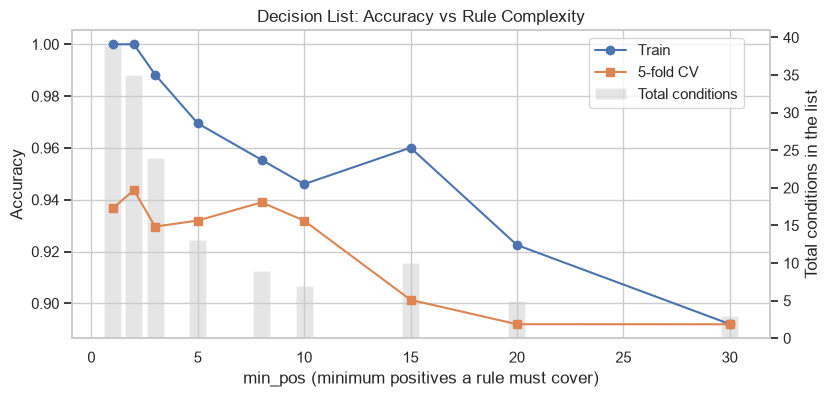

Best CV accuracy = 0.944
Simplest list within 1 point of it: min_pos = 8


In [11]:
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(sweep['min_pos'], sweep['Train acc'], 'o-', label='Train')
ax1.plot(sweep['min_pos'], sweep['CV acc'], 's-', label='5-fold CV')
ax1.set_xlabel('min_pos (minimum positives a rule must cover)')
ax1.set_ylabel('Accuracy')
ax2 = ax1.twinx()
ax2.bar(sweep['min_pos'], sweep['Conditions'], alpha=0.2, color='gray',
        label='Total conditions')
ax2.set_ylabel('Total conditions in the list')
ax2.grid(False)
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)
fig.legend(loc='upper right', bbox_to_anchor=(0.88, 0.88))
plt.title('Decision List: Accuracy vs Rule Complexity')
plt.show()

best_cv = sweep['CV acc'].max()
best_mp = int(sweep.loc[sweep['CV acc'] >= best_cv - 0.01, 'min_pos'].max())
print(f'Best CV accuracy = {best_cv:.3f}')
print(f'Simplest list within 1 point of it: min_pos = {best_mp}')

CV accuracy is almost flat (93–94%) from `min_pos = 1` to 10, while the number of conditions falls from 39 to 7. Since the extra rules buy nothing on unseen data, we take the **simplest list whose CV accuracy is within 1 percentage point of the best** (the same idea as the one-standard-error rule).

## The Learned Decision List

In [12]:
dl = DecisionList(min_pos=best_mp).fit(D_train, yb_train)
dl.show()

R1: IF   worst radius = high
       AND worst concave points = high
       AND worst perimeter = high
     THEN malignant    (training: 113 correct, 0 wrong)
R2: IF   worst radius = high
       AND mean texture = high
     THEN malignant    (training: 13 correct, 0 wrong)
R3: IF   worst concave points = high
       AND mean texture = high
     THEN malignant    (training: 10 correct, 0 wrong)
R4: IF   mean concave points = high
       AND worst texture = mid
     THEN malignant    (training: 8 correct, 4 wrong)
DEFAULT: benign


In [13]:
fired = dl.fired_rule(D_test)
y_pred = dl.predict(D_test)

rows = []
for k in list(range(len(dl.rules))) + [-1]:
    m = fired == k
    rows.append({'Rule': 'default' if k < 0 else f'R{k + 1}',
                 'Predicts': dl.default if k < 0 else dl.rules[k][1],
                 'Test records fired': m.sum(),
                 'Coverage': m.mean(),
                 'Accuracy': (y_pred[m] == yb_test[m]).mean()})
pd.DataFrame(rows).round(3)

,Rule,Predicts,Test records fired,Coverage,Accuracy
0,R1,malignant,37,0.259,1.000
1,R2,malignant,4,0.028,1.000
2,R3,malignant,4,0.028,1.000
3,R4,malignant,1,0.007,1.000
4,default,benign,97,0.678,0.928


Test accuracy: 0.951

              precision    recall  f1-score   support

   malignant       1.00      0.87      0.93        53
      benign       0.93      1.00      0.96        90

    accuracy                           0.95       143
   macro avg       0.96      0.93      0.95       143
weighted avg       0.95      0.95      0.95       143



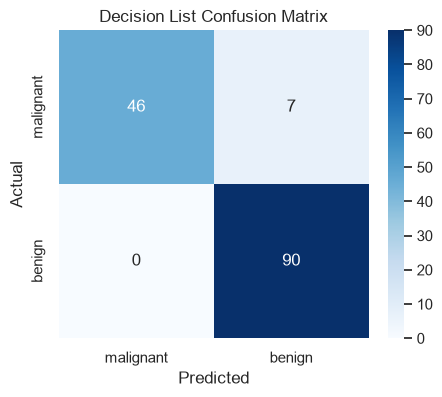

In [14]:
print(f'Test accuracy: {(y_pred == yb_test).mean():.3f}\n')
print(classification_report(yb_test, y_pred,
                            labels=list(cancer.target_names)))

cm = confusion_matrix(yb_test, y_pred, labels=cancer.target_names)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=cancer.target_names, yticklabels=cancer.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Decision List Confusion Matrix')
plt.show()

## Comparison with a Decision Tree

Every root-to-leaf path of a decision tree is also an IF-THEN rule. Below is the depth-3 tree from Assignment 6 written out as text — 7 leaves, i.e. 7 mutually exclusive rules that share and repeat tests.

In [15]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)
print(export_text(tree, feature_names=list(cancer.feature_names),
                  class_names=list(cancer.target_names)))

|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- area error <= 91.56
|   |   |   |--- class: benign
|   |   |--- area error >  91.56
|   |   |   |--- class: malignant
|   |--- worst concave points >  0.14
|   |   |--- worst texture <= 25.62
|   |   |   |--- class: benign
|   |   |--- worst texture >  25.62
|   |   |   |--- class: malignant
|--- worst radius >  16.80
|   |--- texture error <= 0.47
|   |   |--- class: benign
|   |--- texture error >  0.47
|   |   |--- worst concavity <= 0.19
|   |   |   |--- class: benign
|   |   |--- worst concavity >  0.19
|   |   |   |--- class: malignant



In [16]:
def tree_rule_stats(t):
    """Number of leaves (= rules) and total tests over all root-leaf paths."""
    left, right = t.tree_.children_left, t.tree_.children_right
    stack, leaves, conditions = [(0, 0)], 0, 0
    while stack:
        node, depth = stack.pop()
        if left[node] == -1:
            leaves, conditions = leaves + 1, conditions + depth
        else:
            stack += [(left[node], depth + 1), (right[node], depth + 1)]
    return leaves, conditions


tree_rules, tree_conds = tree_rule_stats(tree)
comparison = pd.DataFrame([
    {'Model': f'Decision list (min_pos={best_mp})',
     'Rules': len(dl.rules) + 1,
     'Conditions': sum(len(r) for r, _, _, _ in dl.rules),
     'Test accuracy': (y_pred == yb_test).mean()},
    {'Model': 'Decision tree (depth=3, raw features)',
     'Rules': tree_rules, 'Conditions': tree_conds,
     'Test accuracy': tree.score(X_test, y_test)},
])
comparison.round(3)

,Model,Rules,Conditions,Test accuracy
0,Decision list (min_pos=8),5,9,0.951
1,"Decision tree (depth=3, raw features)",7,20,0.944


## Conclusion

- **FOIL gain by hand = by code:** on Play Tennis the first test chosen is `Humidity = High` (gain 2.71 vs 2.25 for `Outlook = Sunny`), then `Outlook = Sunny` makes the rule pure. Sequential covering finds the textbook list — *IF Humidity = High AND Outlook = Sunny THEN No; IF Outlook = Rain AND Wind = Strong THEN No; ELSE Yes* — with 100% training accuracy.
- **Breast cancer:** the final decision list is just **4 rules + a default (9 conditions)** and scores **95.1%** on the test set — slightly better than the depth-3 decision tree (94.4%, 7 rules, 20 conditions). Rule R1 (IF worst radius, worst concave points and worst perimeter are all high THEN malignant) alone covers 113 of the 159 malignant training tumours with no errors.
- Every malignant prediction is correct (precision 1.00), but 7 of 53 malignant test tumours fall through to the default `benign` rule (recall 0.87) — for screening, missed cancers are the costly error, so a lower `min_pos` or rules for both classes would be worth the extra complexity.
- **Complexity control:** with `min_pos = 1` the list memorises the training set (100% train accuracy, 13 rules, 39 conditions) without generalising any better; raising `min_pos` trades a little training accuracy for far simpler rules, just like limiting tree depth.
- **Decision list vs tree:** list rules are ordered (first match wins), so later rules can stay short; tree rules are unordered and mutually exclusive but repeat the same tests along many paths.
- Limitations: greedy rule growth can miss better combinations, numeric features must be discretised (information is lost at bin edges), and rule order makes later rules harder to read in isolation.